# Composite patterns: RNAs with more than one localisation pattern

Every pairwise combination of six patterns was simulated in the same cell — about 41,000
held-out observations over 15 pairs — and embedded with the published model next to pure
observations of each class. Composites are **not** placed somewhere new: they land inside the
territory the pure classes already span, and what happens there depends on whether the two
patterns stay distinguishable once they share a cell.

For most pairs they do, and the composite sits **between its two parents**. For the four
strongest pairs, 66–91 % of a composite's 25 nearest pure neighbours are its own two parents,
against a 29 % chance rate and the 74 % a *pure* RNA achieves for its own class; 8 of 15 pairs
reach at least half that pure-class reference (§1). Where a composite sits between its parents
tracks how much of each pattern it carries (§2: Spearman ρ positive in 14 of 15 pairs, up to
0.71).

The exception is the nucleus. In four of the five pairs containing `intranuclear`, the composite
is **absorbed into `random`** — 54–81 % of its nearest pure neighbours carry that label. A cell
holding both nuclear and cytoplasmic transcripts has spots over all of it, and `random` is the
only label the vocabulary has for that. `intranuclear × protrusion` is the exception: it keeps
35 % parent neighbours and only 14 % `random`, because a protrusion is a distinctive enough shape
to survive the mixture. Which composites are legible depends on the two specific patterns, not
on composites in general.

**Scope.** These are two-pattern mixtures of clean simulated patterns compared at matched spot
counts; real RNAs will be messier and may combine more than two.

The last cell draws Supp. Fig. 11 from the same data.

**Inputs** (`paths.data("composite_patterns")`): `latents.npy` and `metadata.csv` — 15-dimensional
latents of 40,971 usable composite and 48,370 pure held-out observations, encoded with the
published model by `scripts/composite_patterns/extract_and_encode_composites.py` — and
`examples/`, the 22 example images drawn below.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

import paths
from palette import pattern_palette, composite_colour

DATA = paths.data("composite_patterns")
FIG  = paths.figures("composite_patterns")

# six constituents; `random` is never a constituent but must be in the reference set,
# because a mixture of two complementary patterns is spots everywhere -- which is
# what `random` is. Omitting it forces such a composite onto a wrong nearest class.
CONST = ["cell-edge", "extranuclear", "intranuclear", "pericellular", "perinuclear", "protrusion"]
ANCH  = CONST + ["random"]

COL = pattern_palette()
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRID,
    "font.size":9,"axes.titlesize":10,"figure.dpi":120,
    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})

# latents: 41,398 composite + 48,370 pure held-out observations through the published
# 2-channel model, produced by scripts/composite_patterns/extract_and_encode_composites.py
Z = np.load(DATA / "latents.npy").astype(np.float64)
M = pd.read_csv(DATA / "metadata.csv", dtype={"cell_id": str})
pure = (M.kind.values == "pure"); comp = ~pure
# 427 rows where one constituent drew no spots -- pure images wearing a composite name
deg  = M.degenerate.fillna(False).values.astype(bool)
use  = comp & ~deg

# Every comparison below is made within a spot-count decile. Density is a strong axis
# of this latent space -- pure `perinuclear` alone slides most of the way across the
# gap to `extranuclear` as its spot count rises -- so an unmatched comparison would
# measure density, not pattern.
edges = np.percentile(M.n_spots.values, np.arange(0, 101, 10)); edges[0] -= 1; edges[-1] += 1
BIN = np.digitize(M.n_spots.values, edges[1:-1])

print(f"{len(M):,} held-out observations | {pure.sum():,} pure over {len(ANCH)} classes, "
      f"{use.sum():,} composite over {M.loc[use,'pattern'].nunique()} pairs")
print(f"spot counts matched: pure median {np.median(M.n_spots[pure]):.0f}, "
      f"composite median {np.median(M.n_spots[use]):.0f}")


89,768 held-out observations | 48,370 pure over 7 classes, 40,971 composite over 15 pairs
spot counts matched: pure median 56, composite median 56


### What these patterns, and their combinations, look like

Six patterns give 15 pairs, and the names are hard to picture. One clear example of
each — the highest transcript count available, split as evenly as the simulation allows
between the two constituents.

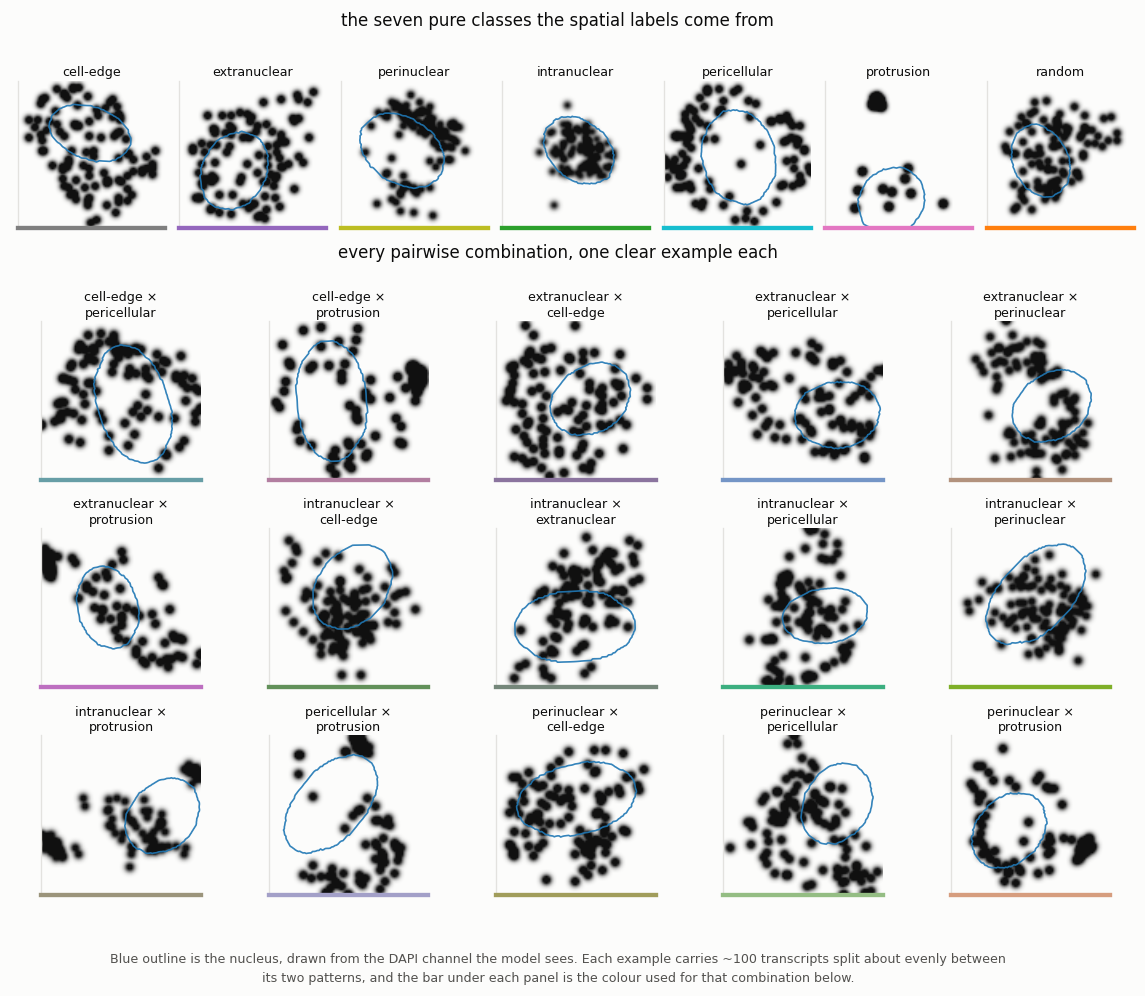

In [2]:
from matplotlib.colors import LinearSegmentedColormap
from skimage.io import imread

# only the 22 images drawn here are shipped: gene channel <obs_key>.tif and DAPI
# channel <obs_key>_DAPI.tif side by side, one folder for pure and one for composite
EXAMPLES = {"pure": DATA / "examples" / "pure", "composite": DATA / "examples" / "composite"}
SPOTS = LinearSegmentedColormap.from_list("spots", [SURFACE, "#101010"])
NUC = "#1f77b4"
SHOW = ["cell-edge", "extranuclear", "perinuclear", "intranuclear",
        "pericellular", "protrusion", "random"]


def pick(pattern, composite):
    """The clearest available example: most transcripts, then most evenly split."""
    d = M[(M.kind == ("composite" if composite else "pure")) & (M.pattern == pattern)]
    if composite:
        d = d[~M.degenerate.fillna(False)].assign(bal=lambda x: (x.f2 - .5).abs())
        return d.sort_values(["n_spots", "bal", "obs_key"], ascending=[False, True, True]).iloc[0]
    return d.sort_values(["n_spots", "obs_key"], ascending=[False, True]).iloc[0]


def panel(ax, r, accent, title):
    root = droot = EXAMPLES[r.kind]
    g = np.asarray(imread(str(root / f"{r.obs_key}.tif")), float)
    d = np.asarray(imread(str(droot / f"{r.obs_key}_DAPI.tif")), float)
    # `protrusion` packs ~90 % of its transcripts into one small region, so a colour
    # scale set by that blob erases every other spot. Square-root the intensities and
    # clip at a low percentile of the occupied pixels instead.
    nz = g[g > 1e-9]
    v = np.percentile(nz, 80) if nz.size else 1.0
    ax.imshow(np.sqrt(np.clip(g / v, 0, 1)), cmap=SPOTS, vmin=0, vmax=1, interpolation="bilinear")
    if d.max() > 0:                    # the DAPI channel is blurred, so contour it
        ax.contour(d, levels=[d.max() * .35], colors=[NUC], linewidths=1.0, alpha=.9)
    ax.set_title(title, fontsize=7.6, pad=3, color=INK, linespacing=1.25)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_color(GRID)
    ax.spines["bottom"].set_color(accent); ax.spines["bottom"].set_linewidth(2.6)


def fig_examples():
    pairs = sorted(M.loc[M.kind == "composite", "pattern"].unique())
    f = plt.figure(figsize=(12.0, 9.0))
    outer = f.add_gridspec(2, 1, height_ratios=[1, 3.15], hspace=.20)
    gt = outer[0].subgridspec(1, 7, wspace=.10)
    gb = outer[1].subgridspec(3, 5, wspace=.10, hspace=.30)
    for j, p in enumerate(SHOW):
        panel(f.add_subplot(gt[0, j]), pick(p, False), COL[p], p)
    for i, pair in enumerate(pairs):
        r = pick(pair, True)
        panel(f.add_subplot(gb[i // 5, i % 5]), r,
              composite_colour(r.pattern_a, r.pattern_b, COL),
              f"{r.pattern_a} ×\n{r.pattern_b}")
    f.text(.5, .915, "the seven pure classes the spatial labels come from",
           ha="center", fontsize=10, color=INK)
    f.text(.5, .700, "every pairwise combination, one clear example each",
           ha="center", fontsize=10, color=INK)
    f.text(.5, .030,
           "Blue outline is the nucleus, drawn from the DAPI channel the model sees. Each example carries ~100 "
           "transcripts split about evenly between\nits two patterns, and the bar under each "
           "panel is the colour used for that combination below.",
           ha="center", fontsize=7.6, color=INK_MUTED, linespacing=1.55)
    f.savefig(FIG / "fig0_examples.png", dpi=200, bbox_inches="tight")
    return f

fig_examples();

## 1. Where a composite lands

For each composite observation, take its 25 nearest neighbours **among pure
observations only**, drawn from the same spot-count decile, and ask what they are. The
reference is what the same measure gives a pure observation looking for its own class.

a pure observation's own-class share among pure neighbours: 0.735
chance, if a composite ignored its parents:                 0.286
mean parent share across the 15 pairs:                      0.392


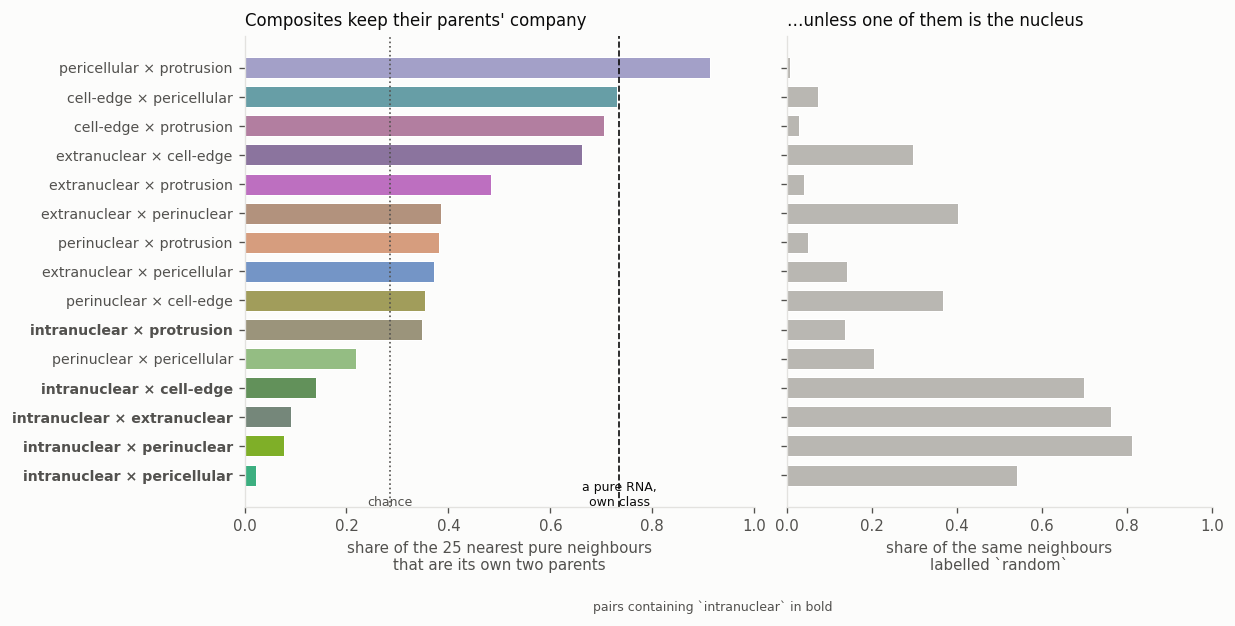

In [3]:
K = 25          # the paper's `sc.pp.neighbors(n_neighbors=25)`
nn_by_bin = {}
for k in range(10):
    idx = np.flatnonzero(pure & (BIN == k))
    nn_by_bin[k] = (idx, NearestNeighbors(n_neighbors=K + 1).fit(Z[idx]))

def pure_neighbours(rows, drop_self=False):
    """Labels of the K nearest PURE observations, matched on spot-count decile."""
    out = np.empty((len(rows), K), dtype=object)
    for k in range(10):
        sel = np.flatnonzero(BIN[rows] == k)
        if not len(sel):
            continue
        idx, nn = nn_by_bin[k]
        _, ind = nn.kneighbors(Z[rows[sel]], n_neighbors=K + (1 if drop_self else 0))
        out[sel] = M.pattern.values[idx[ind[:, 1:] if drop_self else ind]]
    return out

rows = []
for pair in sorted(M.loc[use, "pattern"].unique()):
    q = np.flatnonzero(use & (M.pattern.values == pair))
    lab = pure_neighbours(q)
    a, b = M.pattern_a.values[q[0]], M.pattern_b.values[q[0]]
    sa, sb = (lab == a).mean(1), (lab == b).mean(1)
    rows.append(dict(pair=pair, a=a, b=b, n=len(q),
                     parents=float((sa + sb).mean()), share_a=float(sa.mean()),
                     share_b=float(sb.mean()), random=float((lab == "random").mean(1).mean())))
NB = pd.DataFrame(rows).sort_values("parents")

q = np.random.RandomState(0).choice(np.flatnonzero(pure), 8000, replace=False)
lab = pure_neighbours(q, drop_self=True)
PURE_REF = float(np.mean([(l == o).mean() for l, o in zip(lab, M.pattern.values[q])]))
CHANCE = 2 / len(ANCH)
print(f"a pure observation's own-class share among pure neighbours: {PURE_REF:.3f}")
print(f"chance, if a composite ignored its parents:                 {CHANCE:.3f}")
print(f"mean parent share across the 15 pairs:                      {NB.parents.mean():.3f}")


def fig_neighbourhood():
    f, axes = plt.subplots(1, 2, figsize=(10.4, 5.1), sharey=True,
                           gridspec_kw={"width_ratios": [1.2, 1], "wspace": 0.07})
    y = np.arange(len(NB))
    ax = axes[0]
    ax.barh(y, NB.parents, height=.72, edgecolor="white", linewidth=.6,
            color=[composite_colour(a, b, COL) for a, b in zip(NB.a, NB.b)])
    ax.axvline(CHANCE, color=INK_MUTED, ls=":", lw=1)
    ax.axvline(PURE_REF, color=INK, ls="--", lw=1)
    ax.text(CHANCE, -1.05, "chance", fontsize=7.5, color=INK_MUTED, ha="center")
    ax.text(PURE_REF, -1.05, "a pure RNA,\nown class", fontsize=7.5, color=INK, ha="center")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{a} × {b}" for a, b in zip(NB.a, NB.b)], fontsize=8.5)
    for t, (a, b) in zip(ax.get_yticklabels(), zip(NB.a, NB.b)):
        if "intranuclear" in (a, b):
            t.set_fontweight("bold")
    ax.set_xlim(0, 1); ax.set_xlabel("share of the 25 nearest pure neighbours\nthat are its own two parents")
    ax.set_title("Composites keep their parents' company", loc="left")
    ax = axes[1]
    ax.barh(y, NB["random"], color="#b9b7b2", height=.72, edgecolor="white", linewidth=.6)
    ax.set_xlim(0, 1); ax.set_xlabel("share of the same neighbours\nlabelled `random`")
    ax.set_title("…unless one of them is the nucleus", loc="left")
    f.text(0.5, -0.06, "pairs containing `intranuclear` in bold", ha="center",
           fontsize=7.5, color=INK_MUTED)
    f.savefig(FIG / "fig1_neighbourhood.png", dpi=200, bbox_inches="tight")
    return f

fig_neighbourhood();

The 15 pairs order themselves by how separable the two patterns remain once they
share a cell. Eight reach at least half the pure-class reference, and the top four approach
it outright: their neighbourhood is genuinely made of their own two parents. Four of the
five pairs containing `intranuclear` fall to the bottom, and the neighbours they do have
are mostly `random`.

This is a limit of the vocabulary more than of the embedding. An image holding both
nuclear and cytoplasmic spots has transcripts over the whole cell, and `random` is the
only label the vocabulary has for that. The ordering is not simply
"nuclear versus not", though — `intranuclear × protrusion` sits mid-table, well clear of
the other nuclear pairs, because a protrusion remains visible as a shape even when the
nucleus is also full of transcripts.

## 2. Between the two parents, position tracks the mixture

Both constituents were simulated at pattern-proportion 0.90, so a composite's
composition varies only through its spot counts. `f2 = n2 / (n1 + n2)` runs from about
1:6 to 1:1. If the embedding places a composite *between* its parents rather than merely
*near* them, the balance of the two parents in its neighbourhood should follow `f2`.

positive in 14/15 pairs; median rho 0.289


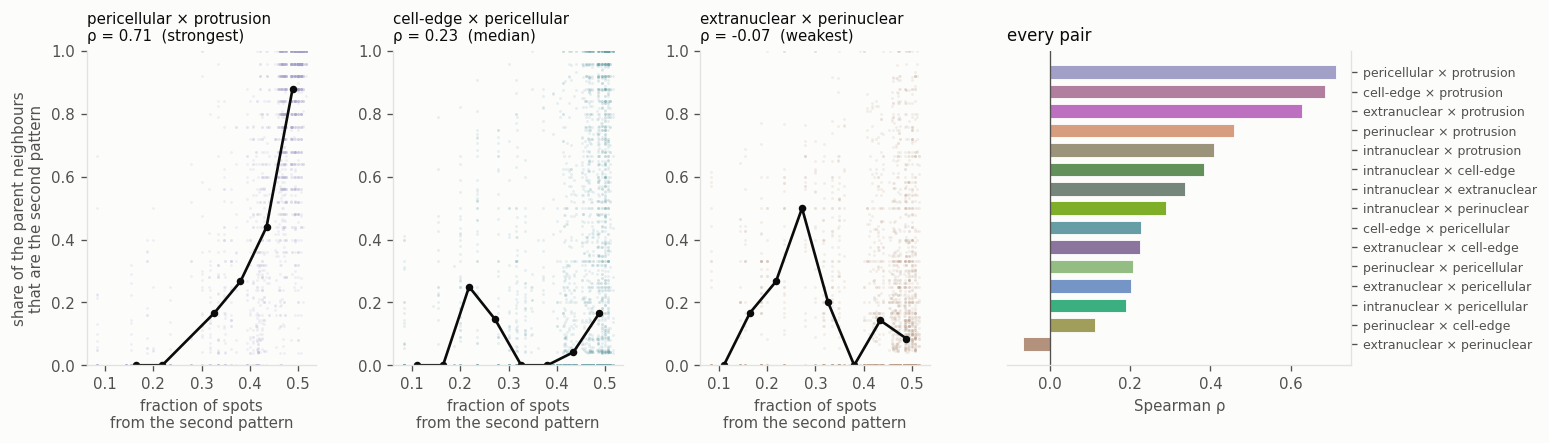

In [4]:
sp, per_obs = [], {}
for pair in sorted(M.loc[use, "pattern"].unique()):
    q = np.flatnonzero(use & (M.pattern.values == pair))
    lab = pure_neighbours(q)
    a, b = M.pattern_a.values[q[0]], M.pattern_b.values[q[0]]
    sa, sb = (lab == a).mean(1), (lab == b).mean(1)
    tot = sa + sb
    ok = tot > 0                       # only where at least one parent is present
    share_b = np.divide(sb, tot, out=np.zeros_like(sb), where=ok)
    rho, p = spearmanr(M.f2.values[q][ok], share_b[ok])
    sp.append(dict(pair=pair, a=a, b=b, n=int(ok.sum()), rho=rho, p=p))
    per_obs[pair] = pd.DataFrame(dict(f2=M.f2.values[q][ok], share_b=share_b[ok]))
SP = pd.DataFrame(sp).sort_values("rho")
print(f"positive in {int((SP.rho > 0).sum())}/{len(SP)} pairs; median rho {SP.rho.median():.3f}")


def lab_for(r):
    o = SP[SP.n >= 1500].sort_values("rho").reset_index(drop=True)
    i = int(o.index[o.pair == r.pair][0])
    return {len(o) - 1: "strongest", 0: "weakest"}.get(i, "median")



def fig_mixture():
    # strongest, median and weakest -- picking the top three would show only
    # `x protrusion` pairs and overstate how general the effect is. Restricted to
    # pairs where enough composites have any parent neighbour at all to bin.
    order = SP[SP.n >= 1500].sort_values("rho").reset_index(drop=True)
    top = order.iloc[[len(order) - 1, len(order) // 2, 0]]
    f, axes = plt.subplots(1, 4, figsize=(13.6, 3.4),
                           gridspec_kw={"width_ratios": [1, 1, 1, 1.5], "wspace": 0.30})
    for ax, (_, r) in zip(axes[:3], top.iterrows()):
        d = per_obs[r.pair]
        c = composite_colour(r.a, r.b, COL)
        ax.scatter(d.f2, d.share_b, s=3, alpha=.14, color=c, linewidths=0, rasterized=True)
        bins = np.linspace(d.f2.min(), d.f2.max(), 9)
        mid, med = [], []
        for lo, hi in zip(bins[:-1], bins[1:]):
            sel = d.share_b[(d.f2 >= lo) & (d.f2 < hi)]
            if len(sel) >= 25:                 # don't draw a median over a handful
                mid.append((lo + hi) / 2); med.append(sel.median())
        ax.plot(mid, med, color=INK, lw=1.6, marker="o", ms=3.5)
        ax.set_title(f"{r.a} × {r.b}\nρ = {r.rho:.2f}  ({lab_for(r)})", loc="left", fontsize=9)
        ax.set_ylim(0, 1); ax.set_xlabel("fraction of spots\nfrom the second pattern")
    axes[0].set_ylabel(f"share of the parent neighbours\nthat are the second pattern")
    ax = axes[3]
    yy = np.arange(len(SP))
    ax.barh(yy, SP.rho, height=.7, edgecolor="white", linewidth=.5,
            color=[composite_colour(a, b, COL) for a, b in zip(SP.a, SP.b)])
    ax.axvline(0, color=INK_MUTED, lw=.8)
    ax.set_yticks(yy); ax.set_yticklabels([f"{a} × {b}" for a, b in zip(SP.a, SP.b)], fontsize=7.5)
    ax.yaxis.tick_right()               # keep the names off the neighbouring panel
    ax.set_xlabel("Spearman ρ"); ax.set_title("every pair", loc="left")
    ax.spines["left"].set_visible(False); ax.spines["right"].set_visible(True)
    ax.spines["right"].set_color(GRID)
    f.savefig(FIG / "fig2_mixture.png", dpi=200, bbox_inches="tight")
    return f

fig_mixture();

The correlation is positive in 14 of 15 pairs, but its strength varies with the
same thing §1 turned on. Where the two patterns are separable it is strong and cleanly
monotone — `pericellular × protrusion` rises from an all-`pericellular` neighbourhood to
an all-`protrusion` one across the range of mixing ratios available. Where they are not,
it is weak or absent: `extranuclear × perinuclear` is flat, and those two patterns are
hard to tell apart even in isolation, both being cell-interior clouds. So a composite's
position carries its composition only to the extent that its two constituents were
distinguishable in the first place.

## Summary

Composite patterns do not break the embedding and do not occupy a space of their own.
They interpolate: a composite of two separable patterns sits between them, in proportion
to how much of each it carries. What the discrete label does is discard that — it is a
collapse of a continuum onto the nearest named class, and for a mixture of two
spatially complementary patterns, the nearest named class is `random`.

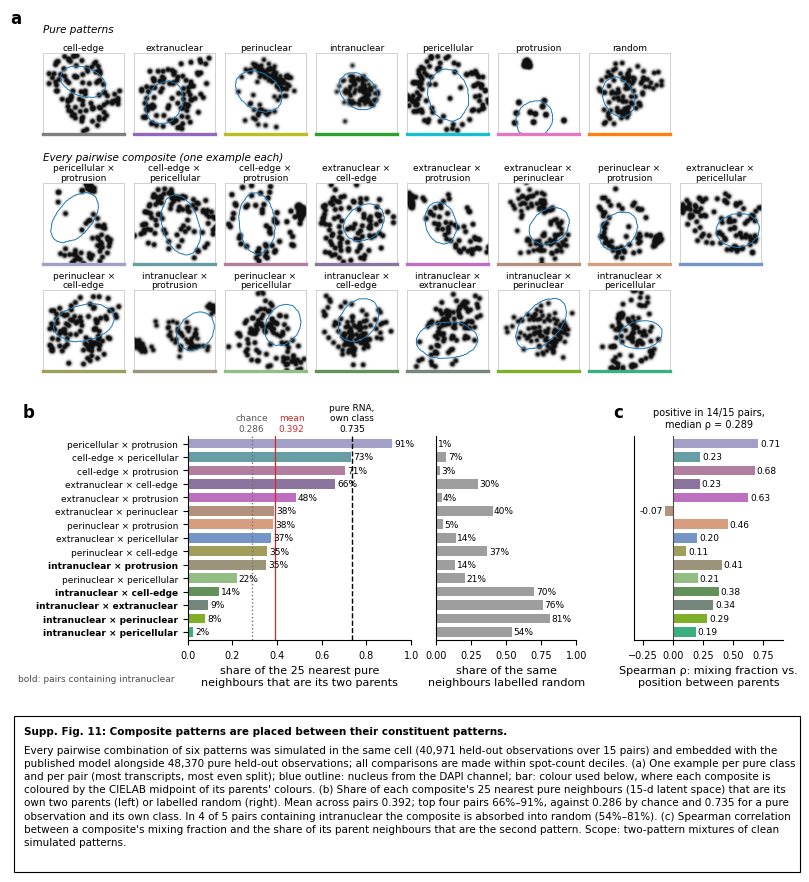

In [5]:
# Supp. Fig. 11, drawn from the data and the neighbourhood measures computed above
from supp_style import new_page, panel_letter, caption_box, save_page, COL
cc = lambda a, b: composite_colour(a, b, COL)

assert (pure.sum(), use.sum(), M.loc[use, "pattern"].nunique()) == (48370, 40971, 15)
# one row per pair: neighbour shares (§1) and the mixing correlation (§2)
NB = (NB[["pair", "a", "b", "n", "parents", "random"]]
      .merge(SP[["pair", "rho"]], on="pair").sort_values("parents").reset_index(drop=True))
MEAN_PAR = NB.parents.mean()
TOP4 = NB.parents.nlargest(4)
NUC = NB[(NB.a == "intranuclear") | (NB.b == "intranuclear")]
NUC_ABS = NUC[NUC["random"] > 0.5]
N_POS = int((NB.rho > 0).sum())
MED_RHO = NB.rho.median()

# cross-check against the tables saved when these measures were first computed
ref = pd.read_csv(DATA / "A2_neighbourhoods.csv").set_index("pair")
assert np.allclose(NB.set_index("pair").parents, ref.parents.loc[NB.pair])
assert np.allclose(NB.set_index("pair")["random"], ref["random"].loc[NB.pair])
refs = pd.read_csv(DATA / "A2b_spearman.csv").set_index("pair")
assert np.allclose(NB.set_index("pair").rho, refs.rho.loc[NB.pair])
assert (round(PURE_REF, 3), round(CHANCE, 3), round(MEAN_PAR, 3)) == (0.735, 0.286, 0.392)
assert (N_POS, round(MED_RHO, 3)) == (14, 0.289)

fig = new_page()

# a: example images -- the seven pure classes, then every pair (same picks as above)
SPOTS_W = LinearSegmentedColormap.from_list("spots", ["white", "#101010"])
NUCC = "#1f77b4"


def show(ax, r, accent, title):
    root = EXAMPLES[r.kind]
    g = np.asarray(imread(str(root / f"{r.obs_key}.tif")), float)
    d = np.asarray(imread(str(root / f"{r.obs_key}_DAPI.tif")), float)
    nz = g[g > 1e-9]
    v = np.percentile(nz, 80) if nz.size else 1.0
    ax.imshow(np.sqrt(np.clip(g / v, 0, 1)), cmap=SPOTS_W, vmin=0, vmax=1, interpolation="bilinear")
    if d.max() > 0:
        ax.contour(d, levels=[d.max() * .35], colors=[NUCC], linewidths=0.7)
    ax.set_title(title, fontsize=6.5, pad=2, linespacing=1.1)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("0.75"); s.set_linewidth(0.5)
    ax.spines["bottom"].set_color(accent); ax.spines["bottom"].set_linewidth(2.4)
    return int(r.n_spots)


W8, X0, GAP = 0.098, 0.06, 0.012
ROWY = [0.888, 0.795, 0.703]
ax_a0 = None
fig.text(X0, 0.973, "Pure patterns", fontsize=7.5, style="italic", va="bottom")
A4R = 8.27 / 11.69
for j, p in enumerate(["cell-edge", "extranuclear", "perinuclear", "intranuclear",
                       "pericellular", "protrusion", "random"]):
    ax = fig.add_axes([X0 + j * (W8 + GAP), ROWY[0], W8, W8 * A4R])
    show(ax, pick(p, False), COL[p], p)
    ax_a0 = ax_a0 or ax
fig.text(X0, 0.864, "Every pairwise composite (one example each)", fontsize=7.5, style="italic", va="bottom")
pairs = NB.sort_values("parents", ascending=False).pair.tolist()   # same order as panel b
for i, pair in enumerate(pairs):
    r = pick(pair, True)
    ax = fig.add_axes([X0 + (i % 8) * (W8 + GAP), ROWY[1 + i // 8] - 0.018, W8, W8 * A4R])
    show(ax, r, cc(r.pattern_a, r.pattern_b), f"{r.pattern_a} ×\n{r.pattern_b}")
panel_letter(fig, ax_a0, "a", dx=-0.04, dy=0.022)

# b, c: neighbour shares and mixing correlation, one row per pair
y = np.arange(len(NB))
cols = [cc(a, b) for a, b in zip(NB.a, NB.b)]
labels = [f"{a} × {b}" for a, b in zip(NB.a, NB.b)]
BY, BH = 0.455, 0.175
ax_b = fig.add_axes([0.235, BY, 0.27, BH])
ax_b.barh(y, NB.parents, color=cols, height=0.72)
ax_b.axvline(CHANCE, color="0.45", ls=":", lw=1)
ax_b.axvline(PURE_REF, color="black", ls="--", lw=1)
ax_b.axvline(MEAN_PAR, color="#d62728", ls="-", lw=0.9)
ax_b.text(CHANCE, len(NB) - 0.2, f"chance\n{CHANCE:.3f}", fontsize=6.5, ha="center", va="bottom", color="0.35")
ax_b.text(MEAN_PAR + 0.015, len(NB) - 0.2, f"mean\n{MEAN_PAR:.3f}", fontsize=6.5, ha="left", va="bottom",
          color="#d62728")
ax_b.text(PURE_REF, len(NB) - 0.2, f"pure RNA,\nown class\n{PURE_REF:.3f}", fontsize=6.5, ha="center",
          va="bottom")
for yi, v in zip(y, NB.parents):
    ax_b.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=6.5)
ax_b.set_yticks(y); ax_b.set_yticklabels(labels, fontsize=6.5)
for t, (a, b) in zip(ax_b.get_yticklabels(), zip(NB.a, NB.b)):
    if "intranuclear" in (a, b):
        t.set_fontweight("bold")
ax_b.set_ylim(-0.6, len(NB) - 0.4)
ax_b.set_xlim(0, 1)
ax_b.set_xlabel("share of the 25 nearest pure\nneighbours that are its two parents")
ax_b.spines[["top", "right"]].set_visible(False)

ax_r = fig.add_axes([0.535, BY, 0.17, BH], sharey=ax_b)
ax_r.barh(y, NB["random"], color="#9e9e9e", height=0.72)
for yi, v in zip(y, NB["random"]):
    ax_r.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=6.5)
ax_r.set_xlim(0, 1)
ax_r.set_xlabel("share of the same\nneighbours labelled random")
ax_r.tick_params(labelleft=False, left=False)
ax_r.spines[["top", "right"]].set_visible(False)
panel_letter(fig, ax_b, "b", dx=-0.20)

ax_c = fig.add_axes([0.775, BY, 0.18, BH], sharey=ax_b)
ax_c.barh(y, NB.rho, color=cols, height=0.72)
ax_c.axvline(0, color="0.3", lw=0.8)
for yi, v in zip(y, NB.rho):
    ax_c.text(v + (0.015 if v >= 0 else -0.015), yi, f"{v:.2f}", va="center",
              ha="left" if v >= 0 else "right", fontsize=6.5)
ax_c.set_xlim(-0.32, 0.92)
ax_c.set_xlabel("Spearman ρ: mixing fraction vs.\nposition between parents")
ax_c.tick_params(labelleft=False, left=False)
ax_c.spines[["top", "right"]].set_visible(False)
ax_c.set_title(f"positive in {N_POS}/{len(NB)} pairs,\nmedian ρ = {MED_RHO:.3f}", fontsize=7)
panel_letter(fig, ax_c, "c", dx=-0.025)
fig.text(0.03, BY - 0.035, "bold: pairs containing intranuclear", fontsize=6.5, color="0.3")

top4 = TOP4.values
nab = NUC_ABS["random"].values
caption_box(fig, BY - 0.065,
    "Supp. Fig. 11: Composite patterns are placed between their constituent patterns.",
    f"Every pairwise combination of six patterns was simulated in the same cell ({use.sum():,} held-out "
    f"observations over {len(NB)} pairs) and embedded with the published model alongside {pure.sum():,} pure "
    "held-out observations; all comparisons are made within spot-count deciles. (a) One example per pure class "
    "and per pair (most transcripts, most even split); blue outline: nucleus from the DAPI channel; bar: colour "
    "used below, where each composite is coloured by the CIELAB midpoint of its parents' colours. (b) Share of each composite's 25 nearest pure neighbours (15-d latent space) that are its own "
    f"two parents (left) or labelled random (right). Mean across pairs {MEAN_PAR:.3f}; top four pairs "
    f"{top4.min():.0%}–{top4.max():.0%}, against {CHANCE:.3f} by chance and {PURE_REF:.3f} for a pure "
    f"observation and its own class. In {len(NUC_ABS)} of {len(NUC)} pairs containing intranuclear the composite "
    f"is absorbed into random ({nab.min():.0%}–{nab.max():.0%}). (c) Spearman correlation between a composite's "
    "mixing fraction and the share of its parent neighbours that are the second pattern. "
    "Scope: two-pattern mixtures of clean simulated patterns.", width_chars=146, fontsize=7.5)
save_page(fig, "11_composite_patterns_total")
fig